**Title:**
Detecting Defective Coffee by ATR-FTIR, Before and After Roasting

**Question:**
Can ATR-FTIR spectra distinguish between defective and defect-free coffee lots, and does that capability persist for roasted coffee?

**Data citation:**
Collazos-Escobar, G. A. et al., *Mid-infrared spectral dataset and
machine learning tools for defect detection in green and roasted coffee*,
Version 5, Mendeley Data (2026), https://doi.org/10.17632/dtd2fggpyp.5,
accessed 2026-11-05. License CC BY 4.0.

   ## Preprocessing
   Raw spectra can differ in overall intensity because of contact with the ATR crystal, the refractive index of the sample, and other instrument and session effects. Trimming to preserve only chemically relevant regions can help visually clean up the spectrum. The 650 - 1800 cm^-1 region is preserved as it contains the fingerprint and carbonyl regions. The 1800 - 2800 cm^-1 region is trimmed as it contains information about triple bonds, which coffee essentially does not contain; this would mostly pick up atmospheric CO2. The 2800-3700 cm^-1 region is preserved as it contains key C-H and O-H stretches. SNV is applied to each spectrum so comparisons between spectra reflect band shapes. 

The following cell loads and describes the raw data to check the shape, range, and units. 

In [1]:
import pandas as pd

data = pd.read_excel("data/Dataset_Raw.xlsx")

def is_number(name):
    try:
        float(name)
        return True
    except ValueError:
        return False

wavenumbers = [c for c in data.columns if is_number(c)]
labels = [c for c in data.columns if c not in wavenumbers]

print(f"{len(data)} rows (one per coffee lot and processing stage)")
print("label columns:", labels)
print(f"{len(wavenumbers)} wavenumber columns, from {wavenumbers[0]} to {wavenumbers[-1]} cm-1")
print("measured variable: ATR-FTIR absorbance (AU)")
print("value range:", data[wavenumbers].min().min(), "to", data[wavenumbers].max().max())

100 rows (one per coffee lot and processing stage)
label columns: ['V1', 'Process', 'Defect status', 'Processing stage', 'Defect category', 'Within category ID', 'Coffee Lot ID']
900 wavenumber columns, from 648.556784 to 3999.433499 cm-1
measured variable: ATR-FTIR absorbance (AU)
value range: -0.013245 to 0.408103


The following cell implements the first trim for the region between 1800 - 2800 cm^-1 and the region above 3700 cm^-1, with a plot of 10 spectra as a first look to compare raw against trimmed, and SNV-processed spectra.

raw: (100, 900)  trimmed: (100, 549)  SNV: (100, 549)


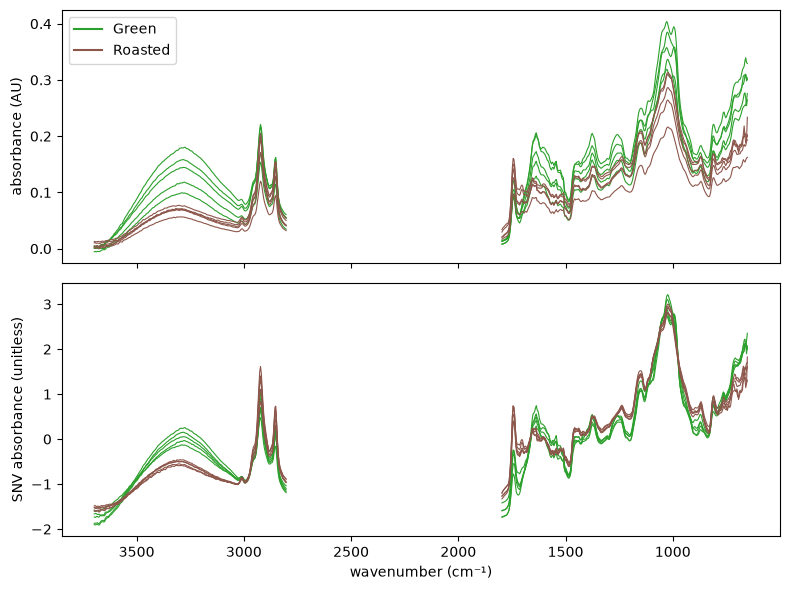

In [2]:
import numpy as np
import pandas as pd
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt

data = pd.read_excel("data/Dataset_Raw.xlsx")

# Split labels from spectra
def is_number(name):
    try:
        float(name)
        return True
    except ValueError:
        return False

wn_cols = [c for c in data.columns if is_number(c)]
labels = data[[c for c in data.columns if c not in wn_cols]]
wn = np.array([float(c) for c in wn_cols])          # cm-1
X_raw = data[wn_cols].to_numpy()                     # absorbance, 100 x 900

# 1. Trim to informative regions
keep = ((wn >= 650) & (wn <= 1800)) | ((wn >= 2800) & (wn <= 3700))
wn_kept = wn[keep]
X_trim = X_raw[:, keep]

# 2. SNV: each spectrum minus its own mean, divided by its own std
X_snv = (X_trim - X_trim.mean(axis=1, keepdims=True)) / X_trim.std(axis=1, keepdims=True)

# 3. Alternative: Savitzky-Golay first derivative (same settings as the authors)
X_d1 = savgol_filter(X_trim, window_length=9, polyorder=3, deriv=1, axis=1)

print("raw:", X_raw.shape, " trimmed:", X_trim.shape, " SNV:", X_snv.shape)

# Put the kept points back on the full grid, with NaN in the removed region,
# so matplotlib leaves a gap instead of drawing a line across it
X_snv_full = np.full(X_raw.shape, np.nan)
X_snv_full[:, keep] = X_snv
X_trim_full = np.where(keep, X_raw, np.nan)

stage = labels["Processing stage"].to_numpy()
colors = {"Green": "tab:green", "Roasted": "tab:brown"}

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
for i in range(0, 100, 10):
    axes[0].plot(wn, X_trim_full[i], lw=0.8, color=colors[stage[i]])
    axes[1].plot(wn, X_snv_full[i], lw=0.8, color=colors[stage[i]])

for s, c in colors.items():
    axes[0].plot([], [], color=c, label=s)
axes[0].legend()
axes[0].set_ylabel("absorbance (AU)")
axes[1].set_ylabel("SNV absorbance (unitless)")
axes[1].set_xlabel("wavenumber (cm⁻¹)")
axes[1].invert_xaxis()
plt.tight_layout()
plt.show()

The following cell creates the same spectra with no trimming for comparison, with the trimmed region shaded.

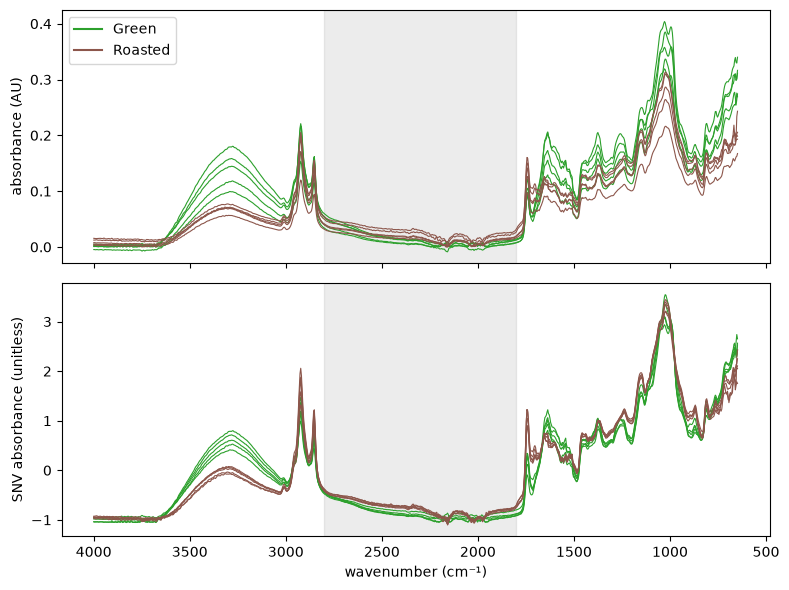

In [3]:
X_snv_untrimmed = (X_raw - X_raw.mean(axis=1, keepdims=True)) / X_raw.std(axis=1, keepdims=True)

stage = labels["Processing stage"].to_numpy()
colors = {"Green": "tab:green", "Roasted": "tab:brown"}

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
for i in range(0, 100, 10):
    axes[0].plot(wn, X_raw[i], lw=0.8, color=colors[stage[i]])
    axes[1].plot(wn, X_snv_untrimmed[i], lw=0.8, color=colors[stage[i]])

for ax in axes:
    ax.axvspan(1800, 2800, color="grey", alpha=0.15)   # shade the region in question

for s, c in colors.items():
    axes[0].plot([], [], color=c, label=s)
axes[0].legend()
axes[0].set_ylabel("absorbance (AU)")
axes[1].set_ylabel("SNV absorbance (unitless)")
axes[1].set_xlabel("wavenumber (cm⁻¹)")
axes[1].invert_xaxis()
plt.tight_layout()
plt.show()

### Parameters for SNV preprocessing
Spectral regions kept for analysis. 1800–2800 cm⁻¹ is excluded because coffee has few bands there (CO2 near 2350 cm⁻¹), and above 3700 cm⁻¹ the spectra are flat.


In [4]:
# Parameters
REGIONS = [(650, 1800),        # cm-1; fingerprint and carbonyl region
           (2800, 3700)]       # cm-1; C-H and O-H stretch region


### SNV preprocessing and class means
Each trimmed spectrum is centred on its own mean and divided by its own standard deviation (SNV), removing offset and multiplicative differences from sample contact. Expected output: the array shapes, and the mean SNV spectrum ± 1 SD for each defect status, one panel per processing stage.


raw: (100, 900)  trimmed: (100, 549)  SNV: (100, 549)


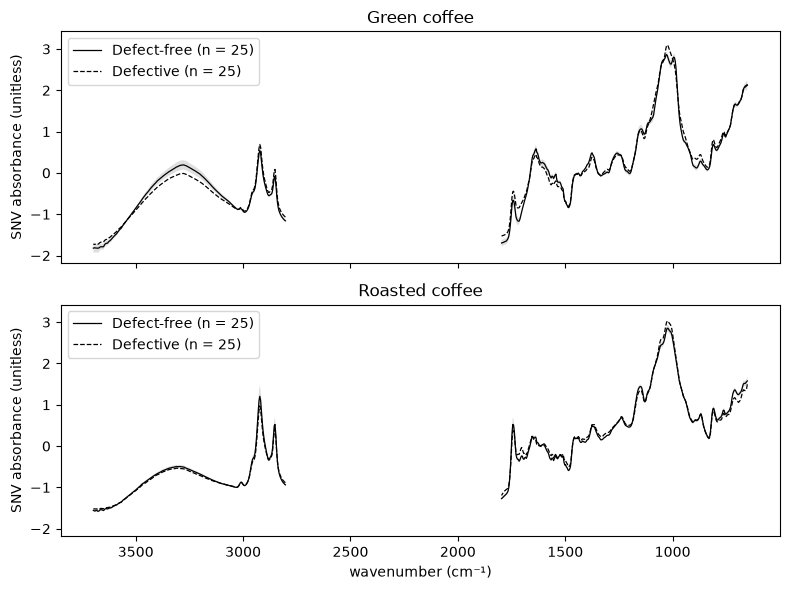

In [5]:
# 1. Trim to the kept regions
keep_snv = np.zeros(wn.shape, dtype=bool)
for low, high in REGIONS:
    keep_snv |= (wn >= low) & (wn <= high)
X_kept = X_raw[:, keep_snv]                                   # absorbance (AU)

# 2. SNV on each spectrum
X_snv_only = ((X_kept - X_kept.mean(axis=1, keepdims=True))
              / X_kept.std(axis=1, keepdims=True))            # unitless

print("raw:", X_raw.shape, " trimmed:", X_kept.shape, " SNV:", X_snv_only.shape)

# Back onto the full grid with NaN in the removed regions, so the plot shows a gap
X_snv_only_full = np.full(X_raw.shape, np.nan)
X_snv_only_full[:, keep_snv] = X_snv_only

# Mean ± 1 SD per defect status, one panel per processing stage
stage = labels["Processing stage"].to_numpy()
status = labels["Defect status"].to_numpy()
line_styles = ["-", "--"]          # one per defect status
hatches = [None, "///"]            # SD band fill, so classes differ without color

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True, sharey=True)
for ax, stage_name in zip(axes, ["Green", "Roasted"]):
    for status_value, ls, hatch in zip(np.unique(status), line_styles, hatches):
        rows = (stage == stage_name) & (status == status_value)
        mean = X_snv_only_full[rows].mean(axis=0)
        sd = X_snv_only_full[rows].std(axis=0)
        ax.fill_between(wn, mean - sd, mean + sd, color="grey",
                        alpha=0.25 if hatch is None else 0.0, hatch=hatch, lw=0)
        ax.plot(wn, mean, ls=ls, lw=0.9, color="black",
                label=f"{status_value} (n = {rows.sum()})")
    ax.set_title(f"{stage_name} coffee")
    ax.set_ylabel("SNV absorbance (unitless)")
    ax.legend()
axes[1].set_xlabel("wavenumber (cm⁻¹)")
axes[1].invert_xaxis()
plt.tight_layout()
plt.show()
